In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import IPython.display as ipd

In [2]:
!git clone --depth 1 https://github.com/karolpiczak/ESC-50.git
DATA_DIR = "ESC-50"
meta = pd.read_csv(f"{DATA_DIR}/meta/esc50.csv")
print(meta.shape)

Cloning into 'ESC-50'...
remote: Enumerating objects: 2018, done.
remote: Counting objects: 100% (2018/2018), done.
remote: Compressing objects: 100% (1798/1798), done.
remote: Total 2018 (delta 215), reused 2009 (delta 214), pack-reused 0 (from 0)
Receiving objects: 100% (2018/2018), 615.62 MiB | 29.37 MiB/s, done.
Resolving deltas: 100% (215/215), done.
Updating files: 100% (2011/2011), done.
(2000, 7)


In [3]:
target_classes = ["crying_baby", "door_wood_knock", "glass_breaking",
                  "siren", "car_horn", "dog", "clock_alarm"]

# Keep the 7 target names; everything else becomes "background"
meta["label"] = meta["category"].where(meta["category"].isin(target_classes), "background")

print(meta["label"].value_counts())

label
background         1720
dog                  40
door_wood_knock      40
clock_alarm          40
car_horn             40
crying_baby          40
glass_breaking       40
siren                40
Name: count, dtype: int64


In [4]:
print(pd.crosstab(meta["label"], meta["fold"]))

fold               1    2    3    4    5
label                                   
background       344  344  344  344  344
car_horn           8    8    8    8    8
clock_alarm        8    8    8    8    8
crying_baby        8    8    8    8    8
dog                8    8    8    8    8
door_wood_knock    8    8    8    8    8
glass_breaking     8    8    8    8    8
siren              8    8    8    8    8


In [5]:
TARGET_SR = 16000
DURATION = 5.0
TARGET_LEN = int(TARGET_SR * DURATION)   # 80,000 samples

def preprocess_audio(y, sr):
    """Convert any audio into a standard format."""
    # 1. Mono (if stereo, average the channels)
    if y.ndim > 1:
        y = np.mean(y, axis=0)

    # 2. Resample to 16 kHz
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)

    # 3. Fix length: pad with zeros or cut
    if len(y) < TARGET_LEN:
        y = np.pad(y, (0, TARGET_LEN - len(y)))
    else:
        y = y[:TARGET_LEN]

    # 4. Peak normalize to range [-1, 1]
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak

    return y.astype(np.float32)

In [6]:
row = meta[meta["category"] == "crying_baby"].iloc[0]
y_raw, sr_raw = librosa.load(f"{DATA_DIR}/audio/{row['filename']}", sr=None)
y_std = preprocess_audio(y_raw, sr_raw)

print("Before: ", y_raw.shape, sr_raw, "Hz, max =", np.abs(y_raw).max())
print("After:  ", y_std.shape, TARGET_SR, "Hz, max =", np.abs(y_std).max())

Before:  (220500,) 44100 Hz, max = 0.94281006
After:   (80000,) 16000 Hz, max = 1.0


In [7]:
fake = np.random.randn(8000) * 0.01      # 0.5 s at 16 kHz, very quiet
out = preprocess_audio(fake, 16000)
print("Shape:", out.shape, "| max:", np.abs(out).max())

Shape: (80000,) | max: 1.0


In [8]:
print("Original (44.1 kHz):")
ipd.display(ipd.Audio(y_raw, rate=sr_raw))
print("Standardized (16 kHz):")
ipd.display(ipd.Audio(y_std, rate=TARGET_SR))

Original (44.1 kHz):


Standardized (16 kHz):


Mel spectrogram shape: (64, 157)


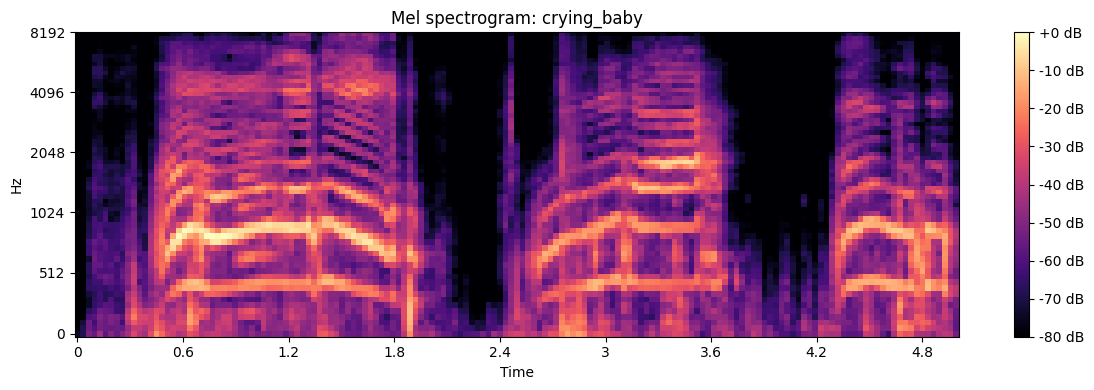

In [9]:
mel = librosa.feature.melspectrogram(y=y_std, sr=TARGET_SR, n_fft=1024,
                                     hop_length=512, n_mels=64)
mel_db = librosa.power_to_db(mel, ref=np.max)

print("Mel spectrogram shape:", mel_db.shape)

plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_db, sr=TARGET_SR, hop_length=512,
                         x_axis="time", y_axis="mel")
plt.colorbar(format="%+2.0f dB")
plt.title("Mel spectrogram: crying_baby")
plt.tight_layout()
plt.show()

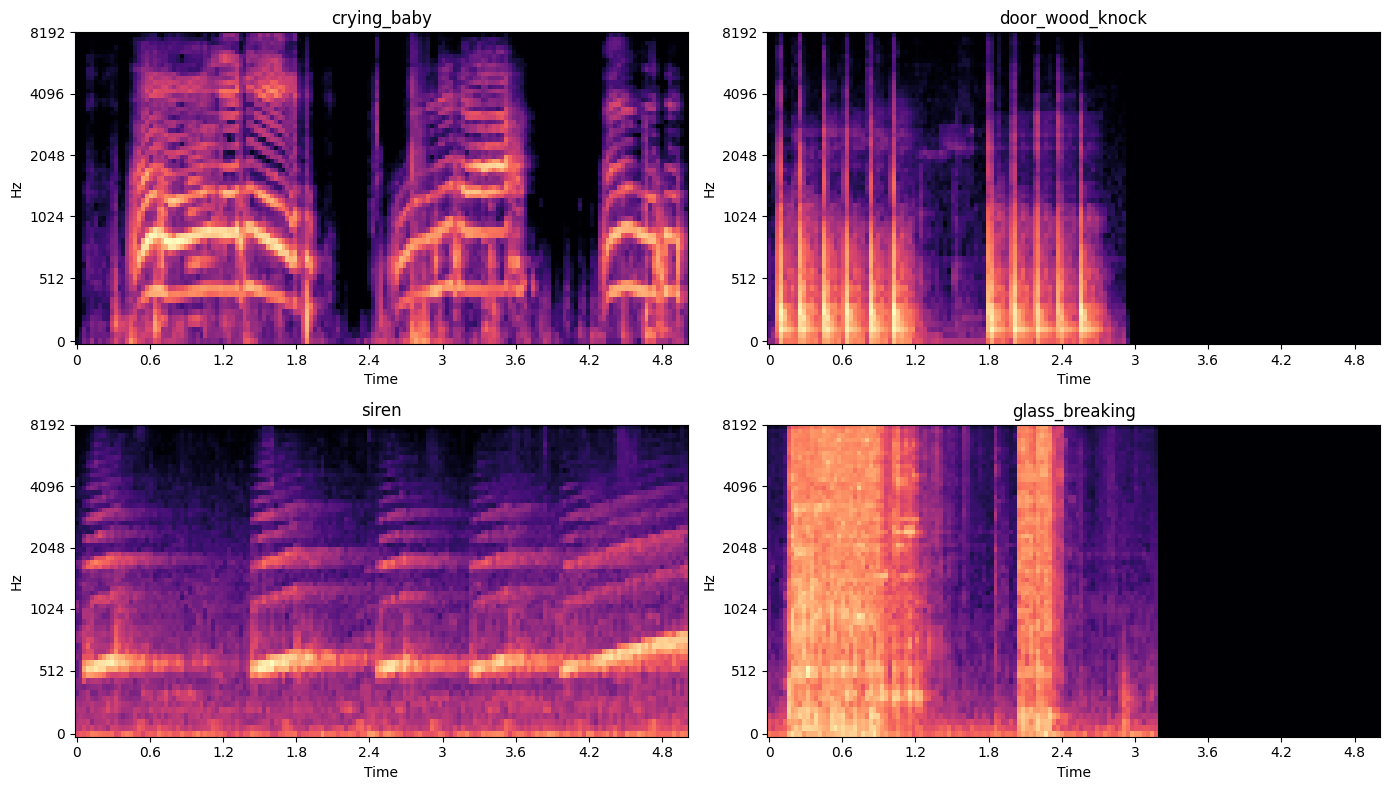

In [10]:
cats = ["crying_baby", "door_wood_knock", "siren", "glass_breaking"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, cat in zip(axes.ravel(), cats):
    r = meta[meta["category"] == cat].iloc[0]
    y_r, sr_r = librosa.load(f"{DATA_DIR}/audio/{r['filename']}", sr=None)
    y_s = preprocess_audio(y_r, sr_r)
    m = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_s, sr=TARGET_SR, n_fft=1024,
                                       hop_length=512, n_mels=64),
        ref=np.max)
    librosa.display.specshow(m, sr=TARGET_SR, hop_length=512,
                             x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(cat)

plt.tight_layout()
plt.show()

In [11]:
N_MFCC = 20

mfcc = librosa.feature.mfcc(y=y_std, sr=TARGET_SR, n_mfcc=N_MFCC,
                            n_fft=1024, hop_length=512, n_mels=64)

print("MFCC shape:", mfcc.shape)

MFCC shape: (20, 157)


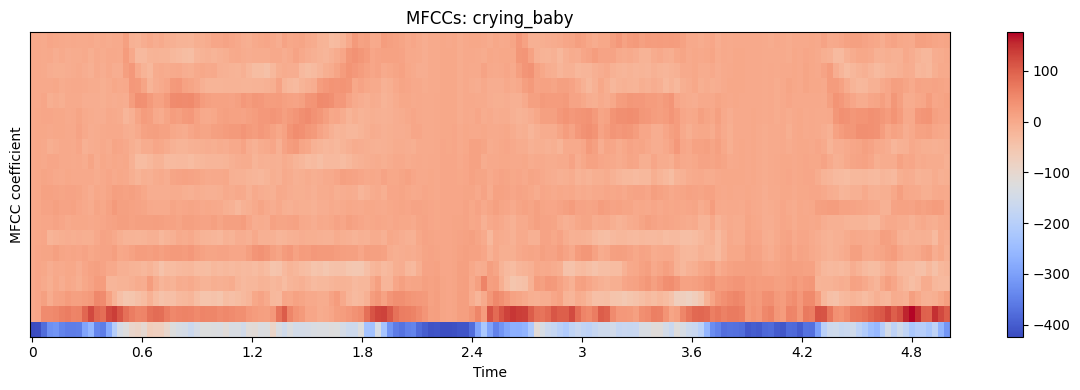

In [12]:
plt.figure(figsize=(12, 4))
librosa.display.specshow(mfcc, sr=TARGET_SR, hop_length=512, x_axis="time")
plt.colorbar()
plt.ylabel("MFCC coefficient")
plt.title("MFCCs: crying_baby")
plt.tight_layout()
plt.show()

In [13]:
def mfcc_features(y_std):
    mfcc = librosa.feature.mfcc(y=y_std, sr=TARGET_SR, n_mfcc=N_MFCC,
                                n_fft=1024, hop_length=512, n_mels=64)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

vec = mfcc_features(y_std)
print("Feature vector shape:", vec.shape)
print("First 5 means:", np.round(vec[:5], 2))

Feature vector shape: (40,)
First 5 means: [-230.34   65.     -5.06    0.26  -13.83]


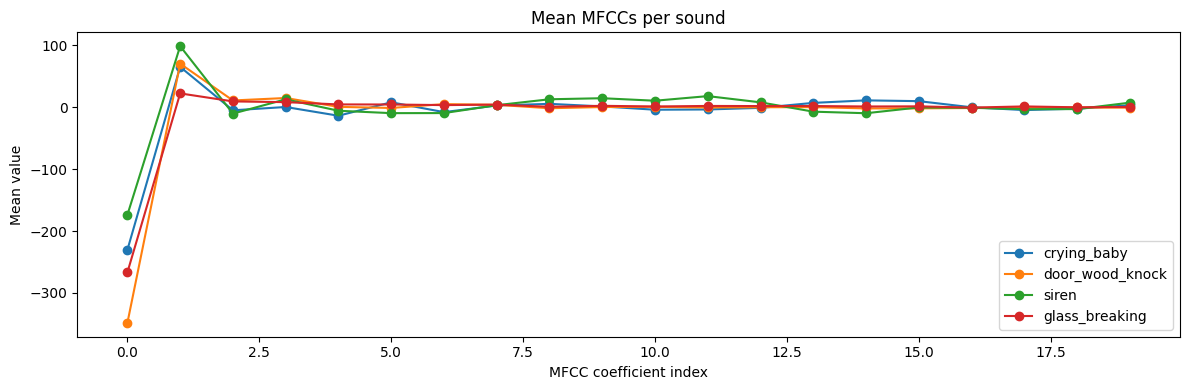

In [14]:
cats = ["crying_baby", "door_wood_knock", "siren", "glass_breaking"]

plt.figure(figsize=(12, 4))
for cat in cats:
    r = meta[meta["category"] == cat].iloc[0]
    y_r, sr_r = librosa.load(f"{DATA_DIR}/audio/{r['filename']}", sr=None)
    v = mfcc_features(preprocess_audio(y_r, sr_r))
    plt.plot(v[:20], marker="o", label=cat)

plt.xlabel("MFCC coefficient index")
plt.ylabel("Mean value")
plt.title("Mean MFCCs per sound")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
from tqdm import tqdm

X, y_labels, folds, filenames = [], [], [], []

for _, row in tqdm(meta.iterrows(), total=len(meta)):
    path = f"{DATA_DIR}/audio/{row['filename']}"
    y_raw, sr_raw = librosa.load(path, sr=None)
    y_std = preprocess_audio(y_raw, sr_raw)
    X.append(mfcc_features(y_std))
    y_labels.append(row["label"])
    folds.append(row["fold"])
    filenames.append(row["filename"])

X = np.array(X)
y_labels = np.array(y_labels)
folds = np.array(folds)

print("X shape:", X.shape)
print("y shape:", y_labels.shape)
print("folds shape:", folds.shape)

100%|██████████| 2000/2000 [00:29<00:00, 67.13it/s]

X shape: (2000, 40)
y shape: (2000,)
folds shape: (2000,)


In [16]:
print("NaN values in X:", np.isnan(X).sum())
print("Infinite values in X:", np.isinf(X).sum())
print("Classes:", np.unique(y_labels))
print("Per-feature min/max of first 3 features:")
print(X[:, :3].min(axis=0), X[:, :3].max(axis=0))

NaN values in X: 0
Infinite values in X: 0
Classes: ['background' 'car_horn' 'clock_alarm' 'crying_baby' 'dog'
 'door_wood_knock' 'glass_breaking' 'siren']
Per-feature min/max of first 3 features:
[-599.3148   -141.78767  -112.025764] [ 30.971582 196.29404   66.3748  ]


In [17]:
os.makedirs("outputs", exist_ok=True)

np.savez_compressed(
    "outputs/mfcc_features.npz",
    X=X,
    y=y_labels,
    folds=folds,
    filenames=np.array(filenames),
)
print("Saved. File size (KB):", os.path.getsize("outputs/mfcc_features.npz") // 1024)

Saved. File size (KB): 302


In [18]:
data = np.load("outputs/mfcc_features.npz")
print("Keys:", list(data.keys()))
print("X:", data["X"].shape, "| y:", data["y"].shape, "| folds:", data["folds"].shape)

Keys: ['X', 'y', 'folds', 'filenames']
X: (2000, 40) | y: (2000,) | folds: (2000,)


In [19]:
from google.colab import files
files.download("outputs/mfcc_features.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
%%writefile audio_processing.py
"""Audio preprocessing for HearMe AI."""
import numpy as np
import librosa

TARGET_SR = 16000
DURATION = 5.0
TARGET_LEN = int(TARGET_SR * DURATION)  # 80,000 samples


def preprocess_audio(y, sr):
    """Convert any audio into a standard format:
    mono, 16 kHz, exactly 5 seconds, peak-normalized to [-1, 1]."""
    # 1. Mono
    if y.ndim > 1:
        y = np.mean(y, axis=0)

    # 2. Resample
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)

    # 3. Fixed length
    if len(y) < TARGET_LEN:
        y = np.pad(y, (0, TARGET_LEN - len(y)))
    else:
        y = y[:TARGET_LEN]

    # 4. Peak normalize
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak

    return y.astype(np.float32)

Writing audio_processing.py


In [21]:
%%writefile feature_extraction.py
"""MFCC feature extraction for HearMe AI."""
import numpy as np
import librosa
from audio_processing import TARGET_SR

N_MFCC = 20
N_FFT = 1024
HOP_LENGTH = 512
N_MELS = 64


def mfcc_features(y_std):
    """Turn a standardized 5-second clip into a 40-number vector
    (20 MFCC means + 20 MFCC standard deviations)."""
    mfcc = librosa.feature.mfcc(
        y=y_std, sr=TARGET_SR, n_mfcc=N_MFCC,
        n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS,
    )
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

Writing feature_extraction.py


In [22]:
import importlib
import audio_processing, feature_extraction
importlib.reload(audio_processing)
importlib.reload(feature_extraction)

row = meta[meta["category"] == "crying_baby"].iloc[0]
y_raw, sr_raw = librosa.load(f"{DATA_DIR}/audio/{row['filename']}", sr=None)

new_vec = feature_extraction.mfcc_features(
    audio_processing.preprocess_audio(y_raw, sr_raw)
)

# Row 0 of your saved features is a different clip, so find this clip's row
idx = filenames.index(row["filename"])
print("Max difference vs. saved features:", np.abs(new_vec - X[idx]).max())

Max difference vs. saved features: 0.0


# Phase 2 Summary: Preprocessing and MFCC Features

- Label set: 7 target classes (crying_baby, door_wood_knock, glass_breaking,
  siren, car_horn, dog, clock_alarm) + background (43 other ESC-50 classes)
- Class counts: 40 per target class, 1,720 background (heavily imbalanced)
- Preprocessing: mono, 16 kHz, 5 s (80,000 samples), peak-normalized
- Features: 20 MFCCs, mean + std over time = 40 features per clip
- Dataset: X (2000, 40), y (2000,), folds (2000,), no NaN or infinite values
- Known limitation: mean/std summaries discard timing and order of events
- Next: train Random Forest and SVM using official folds, with class
  weighting and macro F1 / per-class recall as the main metrics